<center><h1>Радиально-базисные сети


<center>

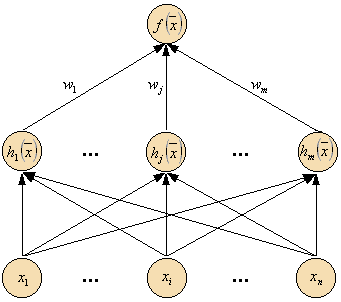

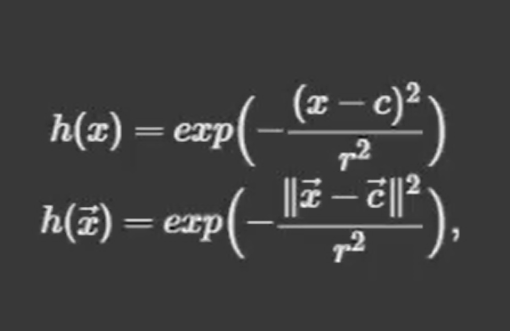
</center>

<text>РБН является полносвязной 3 слойной сетью. Число нейронов в скрытом слоее не более количества входных.

1 Формула - двумерный случай

2 Формула - для векторов

<h2>Обучение РБН

In [1]:
from sklearn import datasets
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
dic_data = datasets.load_iris(as_frame=True)
df = dic_data['frame']
df.head(-1)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
144,6.7,3.3,5.7,2.5,2
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2


In [3]:
df = df.sample(frac=1).reset_index(drop=True)
X = df.iloc[:, :-1]
y = df.target
X_train, X_test, y_train, y_test = X[:130], X[130:], y[:130], y[130:]

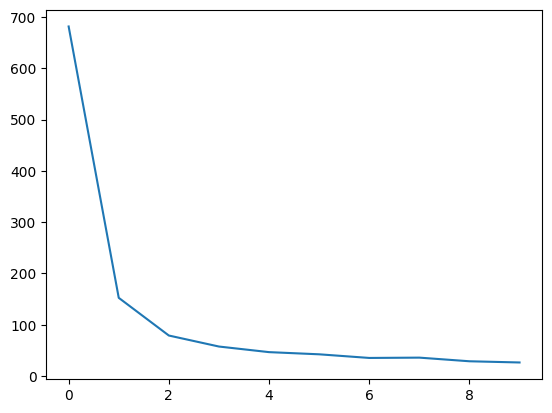

In [4]:
ssd = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=0)
    kmeans.fit(X)
    ssd.append(kmeans.inertia_)

plt.plot(ssd)

In [5]:
k = 3

kmeans = KMeans(n_clusters=k, random_state=0)
km_pred = kmeans.fit_predict(X)
c = kmeans.cluster_centers_
r = [np.linalg.norm((X[km_pred == i] - kmeans.cluster_centers_[i])).mean() 
     for i in range(k)]


In [6]:
class RBF_:
    def __init__(self, X, y, tX, num_of_classes, centroids, std_list):
        self.X = X
        self.y = y
        self.tX = tX
        self.number_of_classes = num_of_classes
        self.centroids = centroids
        self.std_list = std_list
    
    def convert_one_hot(self, x, num_of_classes):
        arr = np.zeros((len(x), num_of_classes))
        for i in range(len(x)):
            c = int(x[i])
            arr[i][c] = 1
        return arr
    
    def rbf(self, x, c, s):
        return np.exp(-1 / (2 * s ** 2) * ((x - c) ** 2).sum())
    
    def rbf_list(self, X, centroids, std_list):
        RBF_list = []
        for x in X:
            RBF_list.append([self.rbf(x, c, s) for (c, s) in zip(centroids, std_list)])
        return np.array(RBF_list)
    
    def fit(self):
        RBF_X = self.rbf_list(self.X, self.centroids, self.std_list)

        self.w = np.linalg.pinv(RBF_X.T @ RBF_X) @ RBF_X.T @ self.convert_one_hot(self.y, self.number_of_classes)
        self.RBF_list_tst = self.rbf_list(self.tX, self.centroids, self.std_list)

    def predict(self):
        pred_ty = self.RBF_list_tst @ self.w
        pred_ty = np.array([np.argmax(x) for x in pred_ty])
        return(pred_ty)

In [7]:
from sklearn.metrics import accuracy_score


model = RBF_(X_train.values, y_train.values, X_test.values, k, centroids=c, std_list=r)
model.fit()
y_pred = model.predict()
accuracy_score(y_test, y_pred)

1.0

<h2>Обучение РБН в PyTorch

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split

In [9]:
X, y = datasets.make_moons(n_samples=4000, noise=.15)
X = (X - X.mean(axis=0)) / X.std(axis=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2)

In [10]:
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train)

In [11]:
num_clusters = 30
kmeans = KMeans(n_clusters=num_clusters)
kmeans.fit(X_train)
centroids = kmeans.cluster_centers_

In [12]:
# Юниформим центроиды
centers = np.random.uniform(-3, 3, (num_clusters, 2))

In [13]:
class RBFNet(nn.Module):
    def __init__(self, num_inputs, num_centers, num_outputs):
        super(RBFNet, self).__init__()
        self.centers = nn.Parameter(torch.tensor(centers))
        self.beta = nn.Parameter(1e-0 * torch.ones((num_centers)))
        self.linear = nn.Linear(num_centers, num_centers)
        self.linear2 = nn.Linear(num_centers, num_outputs)

    def radial_basis_function(self, x, centers, beta):
        x = x.unsqueeze(1)
        centers = centers.unsqueeze(0)
        return torch.exp(-beta * torch.sum((x - centers) ** 2, dim=2))
    
    def forward(self, x):
        rbf_out = self.radial_basis_function(x, self.centers, self.beta)
        out = torch.sigmoid(self.linear(rbf_out.float()))
        out = self.linear2(out)
        return out

In [14]:
model = RBFNet(num_inputs=2, num_centers=num_clusters, num_outputs=2)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=.01)

<h3>Визуализация

In [15]:
from IPython.display import clear_output


def vizualize(model):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                        np.linspace(y_min, y_max, 100))
    
    grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    with torch.inference_mode():
        model.eval()
        Z = model(grid_tensor).argmax(dim=1).numpy()
        Z = Z.reshape(xx.shape)

    centers1 = model.centers.detach().numpy()
    plt.contourf(xx, yy, Z, cmap='jet', alpha=.35)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='jet')
    plt.scatter(centers[:, 0], centers[:, 1], c='yellow', marker='x', label='K-means Centers Init')
    plt.scatter(centers1[:, 0], centers1[:, 1], c='green', marker='x', label='K-means Centers')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.title('Decision Boundary witg Synthetic Data and K-means Centers')
    plt.show()

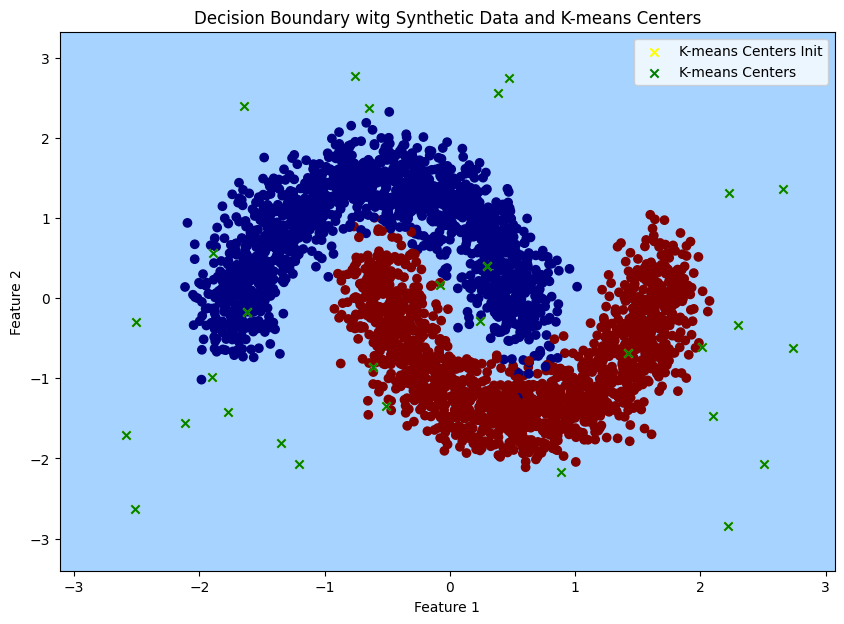

In [16]:
plt.figure(figsize=(10, 7))
vizualize(model)

<h3>Обучение

epoch: 198, loss: 0.020812248811125755


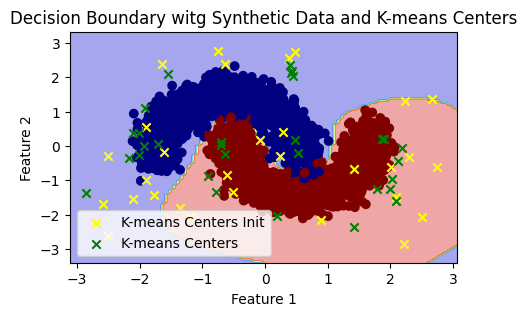

In [17]:
num_epochs = 200
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()

    if epoch % 3 == 0:
        print('epoch: {}, loss: {}'.format(epoch, loss))
        plt.figure(figsize=(5, 3))
        vizualize(model)
        plt.pause(.5)
        clear_output(wait=True)

In [18]:
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.LongTensor(y_test)
with torch.inference_mode():
    model.eval()
    predictions = model(X_test_tensor)
    _, predicted_labels = torch.max(predictions, 1)
    accuracy = torch.sum(predicted_labels == y_test_tensor).item() / y_test_tensor.size(0)
    print(f'Test accuracy: {accuracy * 100:.2f}%')

Test accuracy: 99.38%


<h2>Самоорганизующиеся карты Кахонена

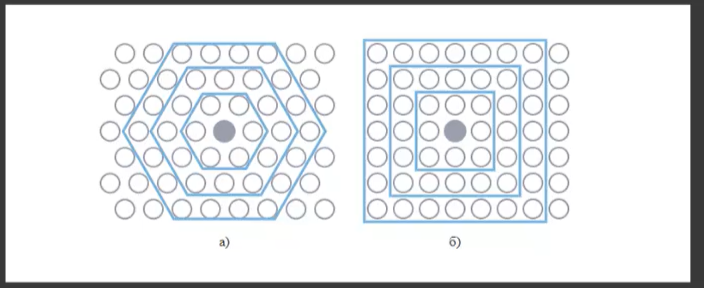

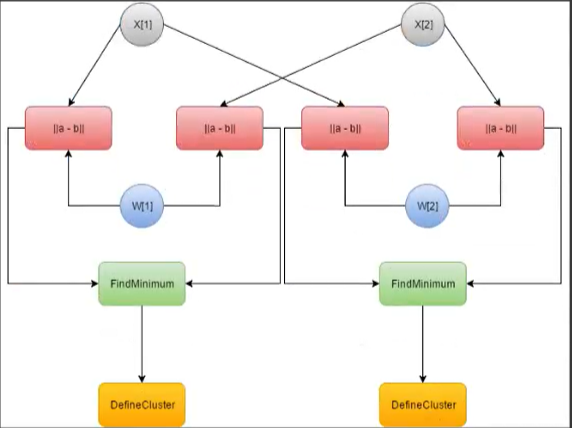

Обучение без учителя, два слоя (входной и выходной). Преобразуем из N-мерного в M-мерное (обычно 2-мерное). Входные переменные число признаков. Выходные - число класстеров
Шаги
1. Инициализируем веса (случайное, из набора и т.д)
2. Выбираем случайный вектор xt
3. Определим нейроны победители (выбираем из них одного случайно) - самый похожий по метрике
4. Определим соседство (у большого изменяет сильнее у меньшеги - слабее) нейронов и изменим веса
5. Вычисляем ошибку карты
6. Останавливаем (по порогу, количество векторов данных кончилось, макс итерации)

$m_i (t) = m_i (t-1) + h(t)(x(t) - m_i (t-1))$

$m_i (t) $ - вектор весов

In [19]:
from tqdm.notebook import tqdm


rand = np.random.RandomState(0)


def find_BMU(SOM, x):
    distSq = (np.square(SOM - x)).sum(axis=2)
    return np.unravel_index(np.argmin(distSq, axis=None), distSq.shape)

def update_weights(SOM, train_ex, learn_rate, radius_sq, BMU_coord, step=3):
    g, h = BMU_coord
    if radius_sq < 1e-3:
        SOM[g, h, :] += learn_rate * (train_ex - SOM[g, h, :])
        return SOM
    for i in range(max(0, g - step), min(SOM.shape[0], g + step)):
        for j in range(max(0, h - step), min(SOM.shape[1], h + step)):
            dist_sq = np.square(i - g) + np.square(j - h)
            dist_func = np.exp(-dist_sq / 2 / radius_sq)
            SOM[i, j, :] += learn_rate * dist_func * (train_ex - SOM[i, j, :])
    return SOM

def train_SOM(SOM, train_data, learn_rate=.1, radius_sq=1, lr_decay=.1,
              radius_decay=.1, epochs=10):
    # decay - это затухание под соответсвующую переменную
    learn_rate_0 = learn_rate
    radius_0 = radius_sq
    for epoch in tqdm(np.arange(0, epochs)):
        rand.shuffle(train_data.copy())
        for train_ex in train_data:
            g, h = find_BMU(SOM, train_ex)
            SOM = update_weights(SOM, train_ex, learn_rate, radius_sq, (g, h))
        learn_rate = learn_rate_0 * np.exp(-epoch * lr_decay)
        radius_sq = radius_0 * np.exp(-epoch * radius_decay)
    return SOM

In [20]:
from PIL import Image


img = datasets.load_sample_image('china.jpg')
img = Image.fromarray(img)
img = img.resize([80, 60])
img = np.array(img, dtype=np.float64) / 255

w, h, d = original_shape = tuple(img.shape)
assert d == 3
train_data = np.reshape(img, (w * h, d))

In [21]:
img[0, 0, 0]

np.float64(0.6862745098039216)

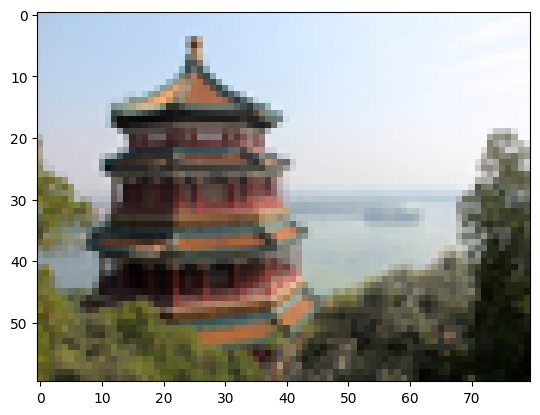

In [22]:
plt.imshow(img)

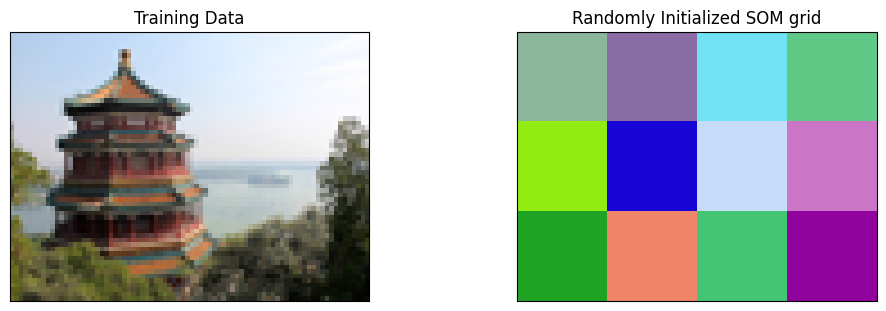

In [23]:
m = 3 # размерность решетки
n = 4

SOM = rand.rand(m, n, 3)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 3.5),
                       subplot_kw=dict(xticks=[], yticks=[]))

ax[0].imshow(img)
ax[0].title.set_text('Training Data')
ax[1].imshow(SOM)
ax[1].title.set_text('Randomly Initialized SOM grid')

Epoch:  1


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:  4


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:  9


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch:  19


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch:  49


  0%|          | 0/30 [00:00<?, ?it/s]

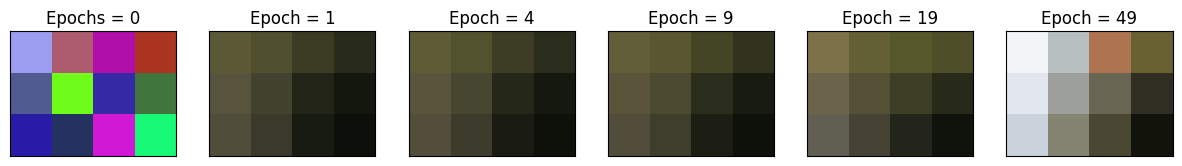

In [24]:
ephs = [1, 3, 5, 10, 30]
n_epchs = len(ephs)

fig, ax = plt.subplots(nrows=1, ncols=n_epchs + 1, figsize=(15, 3.5),
                       subplot_kw=dict(xticks=[], yticks=[]))

total_ephs = 0

SOM = rand.rand(m, n, 3)
i = 0
ax[i].imshow(SOM)
ax[i].title.set_text('Epochs = ' + str(total_ephs))

for epochs, i in zip(ephs, range(1, n_epchs + 1)):
    total_ephs += epochs
    print('Epoch: ', total_ephs)
    SOM = train_SOM(SOM, train_data, epochs=epochs)
    ax[i].imshow(SOM)
    ax[i].title.set_text('Epoch = ' + str(total_ephs))